# Exercise 05.04 - Categorical Data Exploration
You will explore the categorical variables in the Star Wars dataset. Categorical data
exploration helps you understand how different categories are distributed within the dataset
and whether any notable patterns exist between them. Visualizing the relationship between
these variables allows you to uncover exciting trends and better understand the dataset’s
structure.


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

### Exploring data

In [ ]:
df = pd.read_csv("starwarsClean.csv")
print(f"Dataset shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print(f"Categorical columns: {["vehicles", "starships", "homeworld", "hair_color", "sex", "gender", "species"]}")
print(f"Distinct values in Species columns: {df["species"].nunique()}")
print(f"- Total samples: {len(df)}")

print("First few rows:")
print(df.head())

Dataset shape: (87, 14)
Columns: ['name', 'height', 'mass', 'hair_color', 'skin_color', 'eye_color', 'birth_year', 'sex', 'gender', 'homeworld', 'species', 'films', 'vehicles', 'starships']
Categorical columns: ['vehicles', 'starships', 'homeworld', 'hair_color', 'sex', 'gender', 'species']
Distinct values in Species columns: 37
- Total samples: 87
First few rows:
             name  height   mass hair_color   skin_color eye_color  \
0  Luke Skywalker   172.0   77.0      blond         fair      blue   
1           C-3PO   167.0   75.0    Unknown         gold    yellow   
2           R2-D2    96.0   32.0    Unknown  white, blue       red   
3     Darth Vader   202.0  136.0       none        white    yellow   
4     Leia Organa   150.0   49.0      brown        light     brown   

   birth_year     sex     gender homeworld species  \
0        19.0    male  masculine  Tatooine   Human   
1       112.0    none  masculine  Tatooine   Droid   
2        33.0    none  masculine     Naboo   Droid

## – Bar chart for species


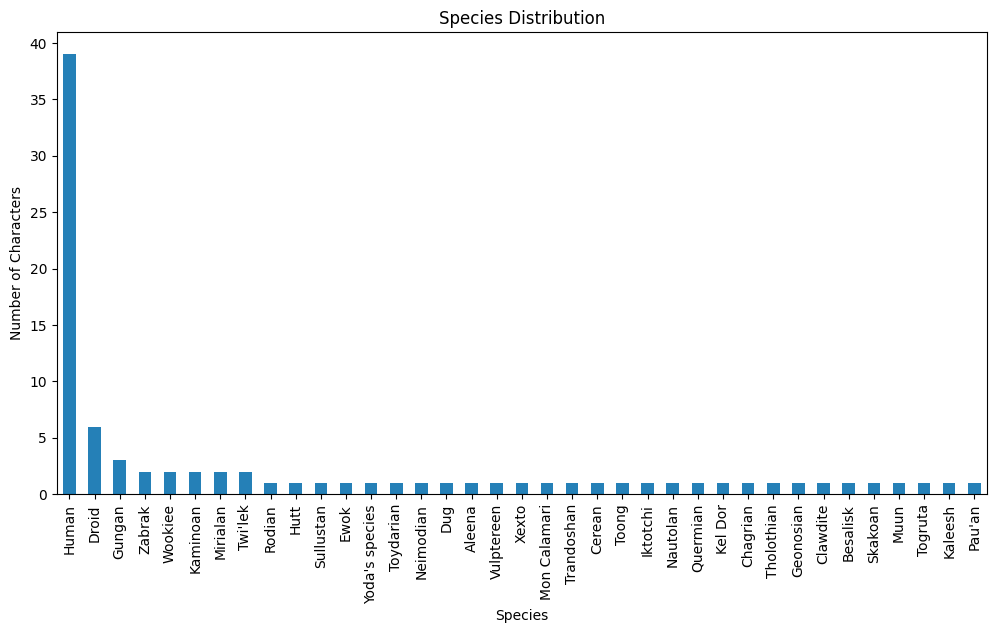

In [ ]:
species_counts = df["species"].value_counts()

plt.figure(figsize=(12, 6))
species_counts.plot(kind="bar", color="#2580B7")

plt.title("Species Distribution")
plt.xlabel("Species")
plt.ylabel("Number of Characters")
plt.show()


Humans is the most common species followed by Droids and Gungans. The remaining species only have 1 or 2 characters. The imputation we made only added 4 extra Humans, so this distribution is not very much affected by the datacleaning.

## - Grouped bar chart for gender distribution by species

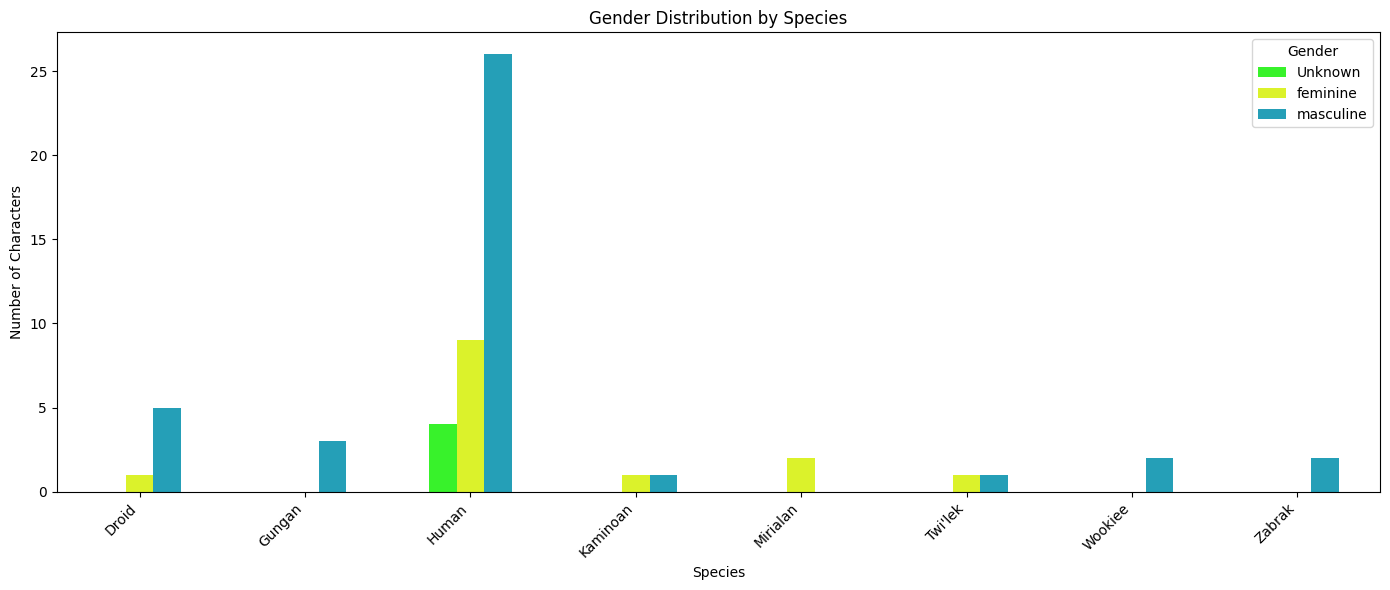

In [ ]:
common = df["species"].value_counts()
common = common[common >= 2].index
df_common = df[df["species"].isin(common)]

gender_counts = pd.crosstab(df_common["species"], df["gender"])

gender_counts.plot(
    kind="bar",
    figsize=(14, 6),
    color=["#38F22B", "#DBF22B", "#259FB7"]
)

plt.title("Gender Distribution by Species")
plt.xlabel("Species")
plt.ylabel("Number of Characters")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()


The chart uses green to define unknown, yellow to define feminine, and blue to define masculine. 
We have filtered out the species that only have 1 character, so this takes us down from 37 bars to 8. 
Generally there is not a balanced gender ratio, with mostly masculine genders. And apart from the 4 imputed unknowns in the Human column, there arent any unknown genders in this visualization.  